In [1]:
import malariagen_data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


In [2]:
af1 = malariagen_data.Af1()

In [4]:
sample_sets = ['1188-VO-NIANG-NIEL-SN-2304-VMF00259', '1330-VO-GN-LAMA-VMF00250',
                  '1315-VO-NG-OMITOLA-OMOL-NG-2008',
                  '1281-VO-CM-CHRISTOPHE-VMF00227', 'AG1000G-KE']

df_samples = af1.sample_metadata(sample_sets=sample_sets, sample_query='taxon == "funestus"')

In [5]:
#Senegal
af1.plot_h12_calibration(
    contig="2RL:58,000,000-100,000,000",
    analysis="funestus",
    sample_sets=sample_sets[0],
)

Load haplotypes:   0%|          | 0/351 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [6]:
#Guinea
af1.plot_h12_calibration(
    contig="2RL:58,000,000-100,000,000",
    analysis="funestus",
    sample_sets=sample_sets[1],
)

Load haplotypes:   0%|          | 0/561 [00:00<?, ?it/s]

Compute H12:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
#Nigeria
af1.plot_h12_calibration(
    contig="2RL:58,000,000-100,000,000",
    analysis="funestus",
    sample_sets=sample_sets[2],
)

In [ ]:
#Cameroon
af1.plot_h12_calibration(
    contig="2RL:58,000,000-100,000,000",
    analysis="funestus",
    sample_sets=sample_sets[3],
)

In [ ]:
#Kenya
af1.plot_h12_calibration(
    contig="2RL:58,000,000-100,000,000",
    analysis="funestus",
    sample_sets=sample_sets[4],
)

In [15]:
SAMPLE_SETS = {
    "Senegal": "1188-VO-NIANG-NIEL-SN-2304-VMF00259",
    "Guinea": "1330-VO-GN-LAMA-VMF00250",
    "Nigeria": "1315-VO-NG-OMITOLA-OMOL-NG-2008",
    "Cameroon": "1281-VO-CM-CHRISTOPHE-VMF00227",
    "Kenya": "AG1000G-KE"
}

WINDOW_SIZES = {
    "Senegal": 1000,
    "Guinea": 2000,
    "Nigeria": 2000,
    "Cameroon": 22000,
    "Kenya": 8000,
}

CHROMS = ["2RL", "3RL", "X"]

regions_list = [
    #'2RL:8000000-9852553',
    #'2RL:40000000-44000000',
    #'2RL:57629228-58000000',
    #'2RL:76000000-76038987',
    #'2RL:80479740-80828789',
    #'3RL:12761557-14664404',
    #'X:8410801-8500000',
    #'X:14432245-15024921'
    '2RL:7538702-10000000',
    '2RL:30040359-48949399',
    '2RL:75127529-77296038',
    '2RL:80000000-81488105',
    '3RL:11605443-16664622',
    'X:8206915-9361059',
    'X:14036167-15263438',
    'X:15611549-17409955'
]

In [16]:
plt.rcParams.update({
    "font.size": 14,          # base size
    "axes.titlesize": 16,     # column titles (2RL, 3RL, X)
    "axes.labelsize": 16,     # axis labels
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
})

In [17]:

OUTDIR = "gwss_cache"
os.makedirs(OUTDIR, exist_ok=True)

def save_gwss(df, pop, chrom):
    path = f"{OUTDIR}/{pop}_{chrom}.csv"
    df.to_csv(path, index=False)

def load_gwss(pop, chrom):
    path = f"{OUTDIR}/{pop}_{chrom}.csv"
    return pd.read_csv(path)

def run_gwss(pop, chrom, use_cache=True, force_recompute=False):

    path = f"{OUTDIR}/{pop}_{chrom}.pkl"

    # Load from cache
    if use_cache and not force_recompute and os.path.exists(path):
        return pd.read_pickle(path)

    # Only compute if needed
    result = af1.h12_gwss(
        contig=chrom,
        window_size=WINDOW_SIZES[pop],
        sample_sets=[SAMPLE_SETS[pop]],
        sample_query='taxon == "funestus"'
    )

    pos = result[0]
    h12 = result[1]

    df = pd.DataFrame({"pos": pos, "h12": h12})
    df["population"] = pop
    df["chrom"] = chrom
    df = df.sort_values("pos")

    df.to_pickle(path)

    return df

def detect_peak_regions(df, distance=100000):

    threshold = df["h12"].quantile(0.995)

    peaks = df[df["h12"] > threshold].copy()
    peaks = peaks.sort_values("pos")

    if peaks.empty:
        return pd.DataFrame(columns=["start", "end"])

    regions = []
    start = peaks.iloc[0]["pos"]
    prev = start

    for pos in peaks["pos"].iloc[1:]:
        if pos - prev > distance:
            regions.append((start, prev))
            start = pos
        prev = pos

    regions.append((start, prev))

    return pd.DataFrame(regions, columns=["start", "end"])


def plot_panel(ax, df, regions_to_shade, pop, chrom, col_idx):

    # scatter
    ax.scatter(df["pos"], df["h12"], s=6, alpha=0.35)

    # smoothing
    window = max(5, WINDOW_SIZES[pop] // 500)
    df["smooth"] = df["h12"].rolling(window, center=True).mean()
    ax.plot(df["pos"], df["smooth"], color="purple", lw=1.2)

    # shaded regions
    for r in regions_to_shade:
        ax.axvspan(r[0], r[1], color="red", alpha=0.2)

    ax.set_ylim(0, 1)
    ax.spines[['top', 'right']].set_visible(False)

    # Y-axis only for first column
    if col_idx != 0:
        ax.yaxis.set_visible(False)
    else:
        ax.set_ylabel(pop)

    # X-axis only for last row (Kenya)
    if pop == list(SAMPLE_SETS.keys())[-1]:
        ax.set_xlabel(f"{chrom} position (bp)")
    else:
        ax.set_xlabel("")
        ax.set_xticklabels([])
        
    if chrom in ["3RL", "X"]:
        ax.yaxis.set_visible(False)
        ax.spines["left"].set_visible(False)
    
    
def parse_regions(regions_list):

    parsed = {}

    for r in regions_list:
        chrom, coords = r.split(":")
        start, end = map(int, coords.split("-"))

        if chrom not in parsed:
            parsed[chrom] = []

        parsed[chrom].append((start, end))

    return parsed

REGIONS_DICT = parse_regions(regions_list)


def region_has_signal(df, region,
                      min_h12=0.08,
                      min_points=5):

    start, end = region
    sub = df[(df["pos"] >= start) & (df["pos"] <= end)]

    if sub.empty:
        return False

    # condition 1: strong peak
    if sub["h12"].max() > 0.05:
        return True

    # condition 2: cluster of moderate values
    high_points = sub[sub["h12"] > min_h12]

    return len(high_points) >= min_points

def get_regions_to_shade(df, chrom):

    regions = REGIONS_DICT.get(chrom, [])

    valid_regions = []

    valid_regions.extend(r for r in regions if region_has_signal(df, r))
    return valid_regions

Load haplotypes:   0%|          | 0/791 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/611 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/141 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/1265 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/977 [00:00<?, ?it/s]

...

Load haplotypes:   0%|          | 0/489 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/113 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/238 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/184 [00:00<?, ?it/s]

Load haplotypes:   0%|          | 0/43 [00:00<?, ?it/s]

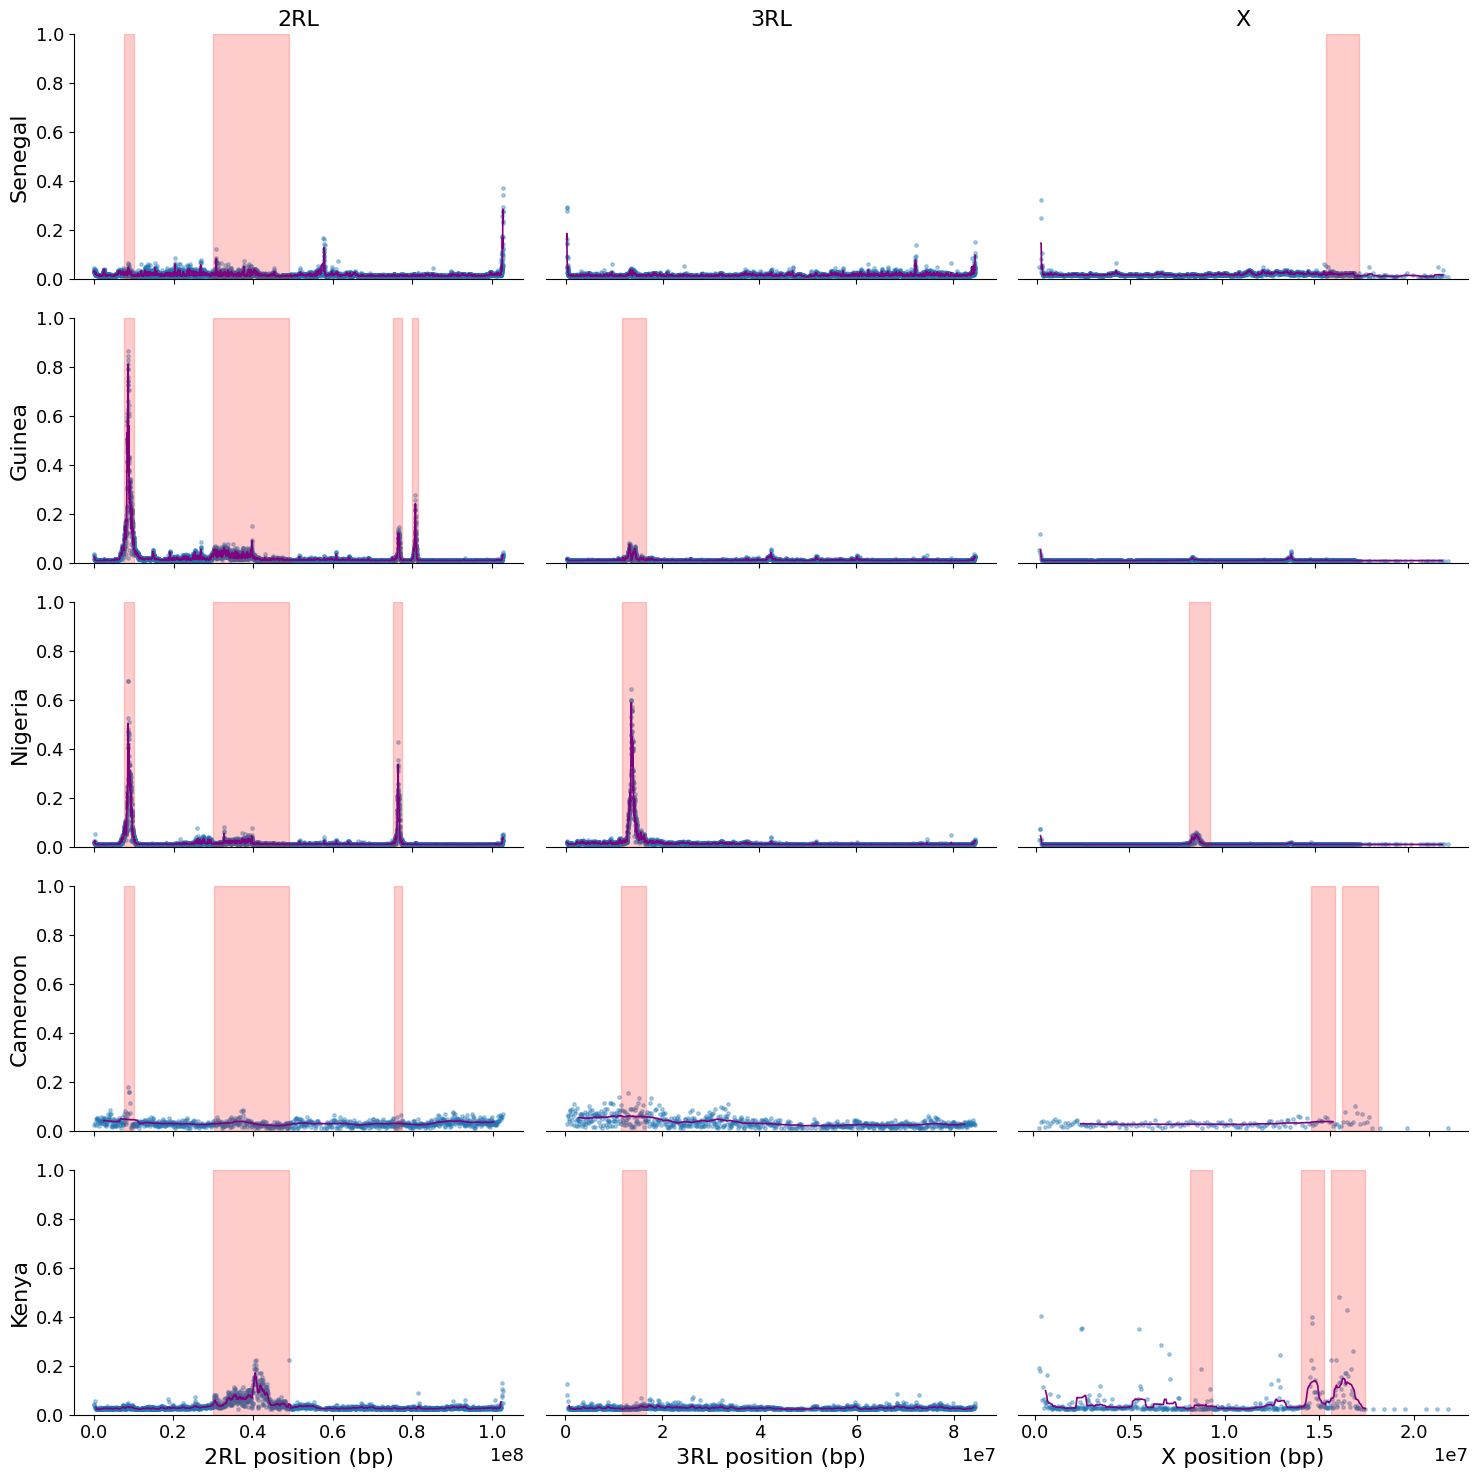

In [18]:
fig, axes = plt.subplots(
    len(SAMPLE_SETS),
    len(CHROMS),
    figsize=(15, 3 * len(SAMPLE_SETS)),
    sharey=True
)

for i, (pop, _) in enumerate(SAMPLE_SETS.items()):
    for j, chrom in enumerate(CHROMS):

        ax = axes[i, j]
        
        df = run_gwss(pop, chrom, use_cache=True)

        regions_to_shade = get_regions_to_shade(df, chrom)

        plot_panel(ax, df, regions_to_shade, pop, chrom, j)

        if i == 0:
            ax.set_title(chrom)

plt.tight_layout()
plt.show()

In [19]:
OUTDIR = "gwss_cache"
os.makedirs(OUTDIR, exist_ok=True)

# -----------------------------
# SAMPLE SETS + WINDOW SIZES
# -----------------------------
SAMPLE_SETS = {
    "Senegal": "1188-VO-NIANG-NIEL-SN-2304-VMF00259",
    "Guinea": "1330-VO-GN-LAMA-VMF00250",
    "Nigeria": "1315-VO-NG-OMITOLA-OMOL-NG-2008",
    "Cameroon": "1281-VO-CM-CHRISTOPHE-VMF00227",
    "Kenya": "AG1000G-KE"
}

WINDOW_SIZES = {
    "Senegal": 1000,
    "Guinea": 2000,
    "Nigeria": 2000,
    "Cameroon": 22000,
    "Kenya": 8000,
}

CHROMS = ["2RL", "3RL", "X"]

# -----------------------------
# REGIONS (LABEL + COLOR)
# -----------------------------
REGIONS_INFO = [
    {"region": "2RL:7538702-10000000", "label": "CYP_Rp1", "color": "#d62728"},
    {"region": "2RL:30040359-48949399", "label": "Cluster A", "color": "#1f77b4"},
    {"region": "2RL:75127529-77296038", "label": "Cluster B", "color": "#2ca02c"},
    {"region": "2RL:80000000-81488105", "label": "Cluster C", "color": "#ff7f0e"},
    {"region": "3RL:11605443-16664622", "label": "GABA", "color": "#9467bd"},
    {"region": "X:8206915-9361059", "label": "Cluster D", "color": "#C1F80A"},
    {"region": "X:14036167-15263438", "label": "CYP9K1", "color": "#e377c2"},
    {"region": "X:15611549-17409955", "label": "Cluster E", "color": "#7f7f7f"},
]

# -----------------------------
# PARSE REGIONS
# -----------------------------
def parse_regions_info(regions_info):

    parsed = {}

    for r in regions_info:
        chrom, coords = r["region"].split(":")
        start, end = map(int, coords.split("-"))

        parsed.setdefault(chrom, []).append({
            "start": start,
            "end": end,
            "label": r["label"],
            "color": r["color"]
        })

    return parsed


REGIONS_DICT = parse_regions_info(REGIONS_INFO)

# -----------------------------
# GWSS LOADER (CACHED)
# -----------------------------
def run_gwss(pop, chrom, use_cache=True):

    path = f"{OUTDIR}/{pop}_{chrom}.pkl"

    if use_cache and os.path.exists(path):
        return pd.read_pickle(path)

    result = af1.h12_gwss(
        contig=chrom,
        window_size=WINDOW_SIZES[pop],
        sample_sets=[SAMPLE_SETS[pop]],
        sample_query='taxon == "funestus"'
    )

    df = pd.DataFrame({
        "pos": result[0],
        "h12": result[1]
    }).sort_values("pos")

    df["population"] = pop
    df["chrom"] = chrom

    df.to_pickle(path)

    return df

# -----------------------------
# SIGNAL DETECTION
# -----------------------------
def region_has_signal(df, region,
                     min_h12=0.08,
                     min_points=5):

    start, end = region

    sub = df.loc[(df["pos"] >= start) & (df["pos"] <= end)]

    if sub.empty:
        return False

    # -----------------------------
    # 1. Strong peak (very clear)
    # -----------------------------
    if sub["h12"].max() > 0.05:
        return True

    # -----------------------------
    # 2. Cluster of moderate values
    # -----------------------------
    high_points = sub[sub["h12"] > min_h12]

    if len(high_points) >= min_points:
        return True

    # -----------------------------
    # 3. Smoothed signal (captures small peaks)
    # -----------------------------
    sub = sub.sort_values("pos")
    smooth = sub["h12"].rolling(5, center=True).mean()

    if smooth.max() > 0.05:
        return True

    return False

# -----------------------------
# FILTER REGIONS
# -----------------------------
def get_regions_to_shade(df, chrom):

    regions = REGIONS_DICT.get(chrom, [])

    return [
        r for r in regions
        if region_has_signal(df, (r["start"], r["end"]))
    ]

# -----------------------------
# PLOTTING FUNCTION
# -----------------------------
def plot_panel(ax, df, regions_to_shade, pop, chrom):

    # scatter
    ax.scatter(df["pos"], df["h12"], s=6, alpha=0.35, color="grey")

    # smoothing (no mutation of original df)
    df_plot = df.copy()
    window = max(5, WINDOW_SIZES[pop] // 500)
    df_plot["smooth"] = df_plot["h12"].rolling(window, center=True).mean()

    ax.plot(df_plot["pos"], df_plot["smooth"], color="black", lw=1.2)

    # shaded regions
    for r in regions_to_shade:
        ax.axvspan(
            r["start"],
            r["end"],
            color=r["color"],
            alpha=0.15
        )

    ax.set_ylim(0, 1)
    ax.spines[['top', 'right']].set_visible(False)

    # Y axis only for 2RL
    if chrom == "2RL":
        ax.set_ylabel(pop, fontsize=12, weight="bold")
    else:
        ax.yaxis.set_visible(False)
        ax.spines["left"].set_visible(False)

    # X axis only for last row
    if pop == list(SAMPLE_SETS.keys())[-1]:
        ax.set_xlabel(f"{chrom} position (bp)", fontsize=12)
    else:
        ax.set_xticklabels([])



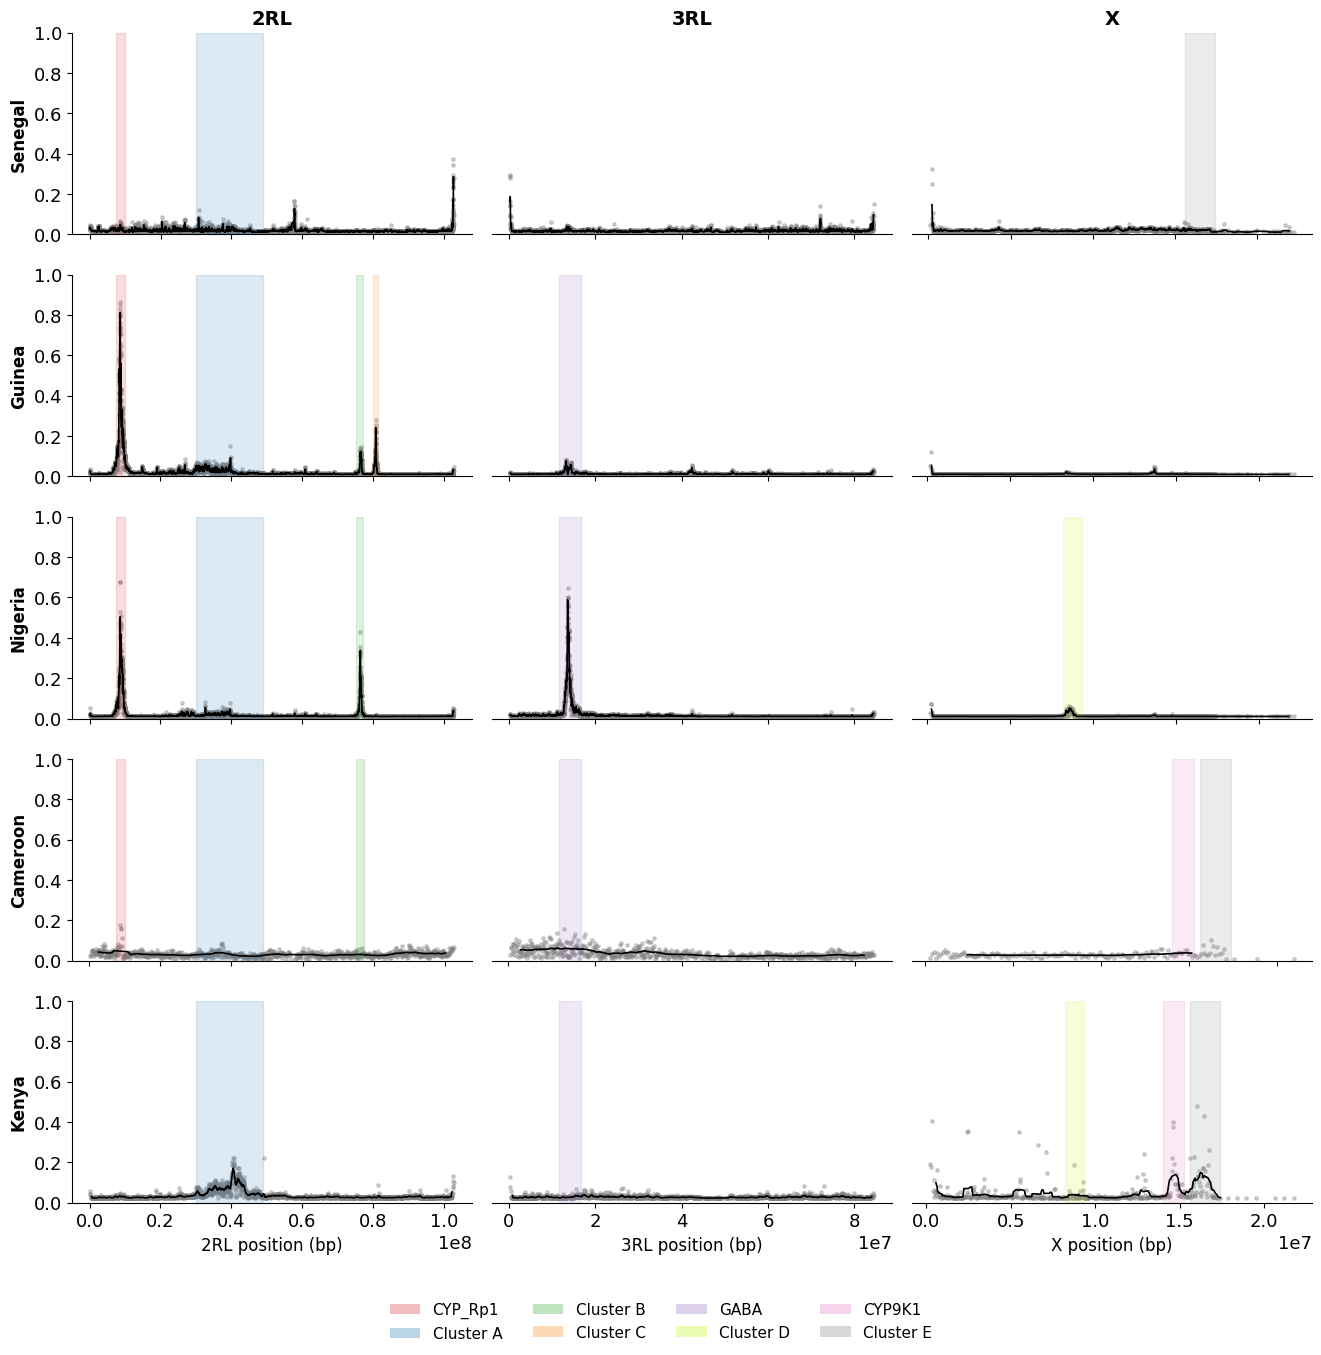

In [20]:
# -----------------------------
# MAIN PLOT
# -----------------------------
fig, axes = plt.subplots(
    len(SAMPLE_SETS),
    len(CHROMS),
    figsize=(16, 3 * len(SAMPLE_SETS)),
    sharey=True
)

for i, (pop, _) in enumerate(SAMPLE_SETS.items()):
    for j, chrom in enumerate(CHROMS):

        ax = axes[i, j]

        df = run_gwss(pop, chrom)
        regions_to_shade = get_regions_to_shade(df, chrom)

        plot_panel(ax, df, regions_to_shade, pop, chrom)

        # column titles
        if i == 0:
            ax.set_title(chrom, fontsize=14, weight="bold")

# -----------------------------
# LEGEND
# -----------------------------
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=r["color"], alpha=0.3, label=r["label"])
    for r in REGIONS_INFO
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=11
)

plt.subplots_adjust(bottom=0.10, wspace=0.05)
#plt.tight_layout()

plt.show()